# TIC 214311908: how far can archival data take one candidate?

TIC 214311908 is the one "new" signal from sector 104 that survives the whole follow-up chain
(notebook 9 §7, `docs/REVIEW_sector104.md`): a 5.69-day, ~1.4 % dip on a nearby (64 pc) M dwarf,
which means a planet of about 4.9 Earth radii. It repeats in six sectors spread over seven years,
and the transit shape gives a stellar density that matches the star's catalogue value. What kept it
from being reported:

* **crowding**: Gaia lists several stars within one TESS pixel (21″), so the dip could come from a
  neighbour rather than the target;
* **the false-positive probability (FPP)**: TRICERATOPS gave 0.64, and 0.85 once background
  stars were included (agent C's TRILEGAL fix). Both are above our reporting bar of 0.5;
* **the pixel evidence**: the robust difference image (notebook 9) puts the flux loss on the target,
  but only at S/N 4.3 against a noise threshold of 4.25 in sector 104.

This notebook asks one question per section and answers it with archival data only:

| § | question | data |
|---|---|---|
| 1 | What TESS data exist? | MAST: light curves, pixel files, FFI cutouts, future pointings |
| 2 | Which neighbours could make a 1.4 % dip at all? | Gaia DR3 within 60″ |
| 3 | Are the target and its neighbours single, constant stars? | Gaia DR3 astrometry, variability, VSX, ASAS-SN |
| 4 | Which star loses the light? | TESS FFI pixels with the TESS PRF model, 6 sectors (`src/pixelfit.py`) |
| 5 | Does the depth change with the aperture as it should? | the same pixels |
| 6 | Can the transit shape rule out faint neighbours? | the multi-sector transit fit |
| 7 | Do other surveys see stars that Gaia missed? | 2MASS, SkyMapper DR4, ExoFOP |
| 8 | What does this do to the FPP? | TRICERATOPS output |
| 9 | What should a ground-based observer do? | predicted transits for the next 6 months |
| 10 | Verdict | |

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord

sys.path.insert(0, "..")
from src import pixelfit as pf

warnings.filterwarnings("ignore")
ROOT = Path("..")
dotenv.load_dotenv(ROOT / ".env")
DATA_DIR = ROOT / "data"
OUT = DATA_DIR / "followup" / "214311908"
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 220)

TIC = 214311908
GAIA_TARGET = 5925373272850784768
summary = json.loads((OUT / "summary.json").read_text())
fit = summary["fit"]
P, T0 = fit["P"]["median"], fit["T0"]["median"]
k = fit["k"]["median"]
chain = np.load(OUT / "fit_samples.npz")["chain"]  # columns: T0, P, k, b, log10(a/R*), q1, q2
star = pd.read_parquet(DATA_DIR / "targets" / "sector_104.parquet").set_index("tic_id").loc[TIC]

# total duration T14 from the fit, for the in-transit windows used below
t0_, P_, k_, b_, la_ = chain[:, :5].T
a_ = 10 ** la_
inc_ = np.arccos(b_ / a_)
def t_contact(x):
    return P_ / np.pi * np.arcsin(np.clip(np.sqrt(np.clip(x**2 - b_**2, 0, None)) / (a_ * np.sin(inc_)), 0, 1))
T14, T23 = t_contact(1 + k_), t_contact(1 - k_)
DUR14 = float(np.median(T14))  # total duration (first to fourth contact), days
DUR_IN = float(np.median(T23))  # full-depth part (second to third contact): the in-transit window for the pixels
print(f"TIC {TIC}: Tmag {star.tmag:.2f}, Teff {star.teff:.0f} K, R* {star.rad:.2f} Rsun, M* {star.mass:.2f} Msun, "
      f"d = {star.dist_pc:.1f} pc")
print(f"ephemeris (all six sectors): P = {P:.6f} +/- {fit['P']['plus']:.6f} d, T0 = {T0:.4f} +/- {fit['T0']['plus']:.4f} BTJD")
print(f"Rp/R* = {k:.3f}  ->  Rp = {fit['rp_earth']['median']:.1f} Rearth, depth ~ {k**2 * 1e6:,.0f} ppm, "
      f"T14 = {DUR14 * 24:.2f} h, T23 = {DUR_IN * 24:.2f} h; stellar density from the fit / catalogue = {fit['rho_ratio_median']:.2f}")

TIC 214311908: Tmag 13.01, Teff 3301 K, R* 0.38 Rsun, M* 0.37 Msun, d = 64.2 pc
ephemeris (all six sectors): P = 5.691498 +/- 0.000006 d, T0 = 3852.2989 +/- 0.0011 BTJD
Rp/R* = 0.117  ->  Rp = 4.9 Rearth, depth ~ 13,686 ppm, T14 = 1.71 h, T23 = 1.22 h; stellar density from the fit / catalogue = 0.94


## 1. What TESS data exist?

The best data for a crowded field would be 2-minute or 20-second **target pixel files** (TPFs), which
SPOC makes only for stars on a target list. A star without a TPF has only the full-frame images
(FFIs), which come at 30 minutes (sector 12), 10 minutes (sector 39) and 200 seconds (sectors 66
onward). From the FFIs we can get **cutouts** (TESScut) and the light curves made from them by
QLP and other high-level science products (HLSPs).

We also ask `tess-point` which sectors will see the star, to know whether new data are coming.

In [2]:
import lightkurve as lk
from tess_stars2px import tess_stars2px_function_entry as tess_stars2px

lcs = lk.search_lightcurve(f"TIC {TIC}")
tpfs = lk.search_targetpixelfile(f"TIC {TIC}")
cuts = lk.search_tesscut(f"TIC {TIC}")
inv = lcs.table.to_pandas()[["mission", "author", "exptime"]]
print(f"light curves on MAST: {len(lcs)}; target pixel files: {len(tpfs)}; TESScut sectors: {len(cuts)}")
print(inv.groupby(["mission", "exptime"])["author"].apply(lambda a: ", ".join(sorted(set(a)))).to_string())
point = tess_stars2px(TIC, star.ra, star.dec)
print("\nsectors in tess-point's pointing table:", sorted({int(s) for s in point[3]}))

light curves on MAST: 11; target pixel files: 0; TESScut sectors: 6
mission          exptime
TESS Sector 103  200.0                               QLP
TESS Sector 104  200.0                               QLP
TESS Sector 12   1800.0     GSFC-ELEANOR-LITE, QLP, TARS
TESS Sector 39   600.0                         QLP, TARS
TESS Sector 66   200.0                         QLP, TARS
TESS Sector 93   200.0                         QLP, TARS

sectors in tess-point's pointing table: [12, 39, 66, 93, 103, 104]


**What this says.** Six sectors, all FFI-only: the star was never on a 2-minute target list, so
there are no TPFs and no SPOC light curves. The HLSPs (QLP, TARS, eleanor-lite) are all built from
the same FFIs, so they add no independent photons. `tess-point` lists no sector after 104, so no
new TESS data are expected soon (this depends on how far ahead its pointing table goes). Everything
below therefore uses the six FFI cutouts. Sector 12 has 30-minute cadence, so only one or two
points fall inside each 1.7-hour transit: it carries little weight.

## 2. Which neighbours could make a 1.4 % dip at all?

If a neighbour causes the dip, its light is diluted by the target's (and everyone else's) light in
the aperture. The QLP light curve is already corrected for the contaminating light that the TIC
predicts (it is "deblended" to the target), so its depth δ is the depth **on the target**. The same
lost flux on a neighbour that is ΔT magnitudes fainter means an eclipse depth of

$$\delta_\text{needed} = \delta \times 10^{0.4\,\Delta T}.$$

A star that would need more than 100 % (it would have to disappear completely, and more) cannot be
the source. This is a quick test that needs only magnitudes. We use Gaia DR3 (positions at epoch
2016.0; the TIC itself is from Gaia DR2) and convert G and BP−RP to the TESS band with the Stassun
et al. (2019) relation.

In [3]:
from astroquery.vizier import Vizier

gfile = OUT / "gaia_dr3_60arcsec.csv"
if gfile.exists():
    gaia = pd.read_csv(gfile)
else:
    cols = ["Source", "RA_ICRS", "DE_ICRS", "Gmag", "BP-RP", "Plx", "e_Plx", "pmRA", "pmDE", "RUWE", "IPDfmp",
            "IPDgofha", "NSS", "RV", "e_RV", "VarFlag", "Dup"]
    c0 = SkyCoord(star.ra, star.dec, unit="deg")
    gaia = Vizier(columns=cols, row_limit=-1).query_region(c0, radius=75 * u.arcsec, catalog="I/355/gaiadr3")[0].to_pandas()
    gaia.to_csv(gfile, index=False)
tg = gaia[gaia.Source == GAIA_TARGET].iloc[0]
gaia["sep"] = SkyCoord(tg.RA_ICRS, tg.DE_ICRS, unit="deg").separation(
    SkyCoord(gaia.RA_ICRS.values, gaia.DE_ICRS.values, unit="deg")).arcsec
gaia = gaia[gaia.sep <= 60].sort_values("sep").reset_index(drop=True)
gaia["Tmag"] = pf.gaia_tmag(gaia.Gmag.values, gaia["BP-RP"].values)
gaia["dT"] = gaia.Tmag - gaia.loc[0, "Tmag"]
DEPTH = k**2
gaia["depth_needed"] = DEPTH * 10 ** (0.4 * gaia.dT)
gaia["can_cause"] = gaia.depth_needed < 1
print(f"{len(gaia)} Gaia DR3 sources within 60\"; {gaia.can_cause.sum() - 1} neighbours bright enough to cause a "
      f"{DEPTH * 1e6:,.0f}-ppm dip (the rest would need > 100 %)")
gaia.loc[gaia.can_cause, ["Source", "sep", "Gmag", "BP-RP", "Tmag", "dT", "Plx", "pmRA", "pmDE", "RUWE",
                          "depth_needed"]].round(3)

271 Gaia DR3 sources within 60"; 52 neighbours bright enough to cause a 13,686-ppm dip (the rest would need > 100 %)


,Source,sep,Gmag,BP-RP,Tmag,dT,Plx,pmRA,pmDE,RUWE,depth_needed
0,5925373272850784768,0.000,14.281,2.756,13.134,0.000,15.497,-113.671,85.544,1.076,0.014
1,5925373272827260544,3.134,17.484,1.316,16.825,3.691,0.655,2.560,-0.976,1.059,0.410
6,5925373272827262208,5.719,17.675,0.957,17.178,4.044,0.282,0.697,-3.981,0.978,0.568
11,5925373272827256448,10.569,18.392,2.020,17.465,4.331,0.009,0.069,-3.460,1.053,0.739
13,5925373272827253632,11.354,15.741,NaN,15.311,2.177,NaN,NaN,NaN,NaN,0.102
14,5925373272850782208,11.728,14.654,2.878,13.476,0.342,16.413,-112.796,87.205,13.717,0.019
15,5925373272827256576,11.993,17.008,1.129,16.431,3.297,-0.012,-0.836,-4.918,1.277,0.285
19,5925373234168931072,13.462,17.833,1.046,17.294,4.160,0.234,-4.685,0.720,0.920,0.631
25,5925373268528684288,17.836,12.661,4.684,11.452,-1.682,0.150,-5.964,-7.063,0.838,0.003
37,5925373234168929792,21.040,17.711,1.013,17.187,4.053,0.132,-2.647,-7.950,1.010,0.572


Most of the 60″ circle is ruled out at once: the sources are too faint. Several neighbours are left,
and three groups matter:

* **the co-moving companion**, Gaia DR3 5925373272850782208 at 11.7″, G = 14.65. Its parallax
  (16.4 ± 0.4 mas against the target's 15.50 ± 0.03) and proper motion (−112.8, +87.2 against
  −113.7, +85.5 mas/yr) are the target's. It is a **physical companion**: a wide binary about
  750 au apart in projection. Next to it (0.4″ away) Gaia lists a second source, G = 15.7, with only
  a two-parameter solution. As a host it would need only a ~2 % eclipse;
* **a bright, very red star** at 17.8″ (G = 12.66, BP−RP = 4.7, parallax 0.15 mas: a distant giant
  behind a lot of dust). It is TIC 214311906, the star TRICERATOPS blames most (§8). It would need only
  a ~0.3 % dip;
* **two faint stars 3–5″ away** (G = 17.5 and 17.7, i.e. Tmag ≈ 16.8 and 17.2, distant background
  stars with parallax < 1 mas). They would need 40–60 % eclipses, which only an eclipsing binary
  can give. These were the "neighbours at 3–5″" that left the candidate unresolved.

## 3. Are the target and its neighbours single, constant stars?

Gaia DR3 offers several warning signs that a "star" is really two stars, or is variable:

* **RUWE** (renormalised unit weight error): about 1 for a well-behaved single star. Above ~1.4 the
  astrometry does not fit a single point source; this often means an unresolved companion closer than
  ~1″;
* **ipd_frac_multi_peak** (`IPDfmp`, %) and **ipd_gof_harmonic_amplitude** (`IPDgofha`): the
  fraction of Gaia scans that saw two peaks, and how much the image shape changes with scan angle.
  Both flag close doubles;
* **non_single_star** (`NSS`): Gaia fitted an orbit;
* **phot_variable_flag** (`VarFlag`) and the DR3 variability tables (classifier, eclipsing binaries).

We also look up the VSX and ASAS-SN variable-star catalogues. An eclipsing binary at P or 2P among
the neighbours would settle the case at once.

In [4]:
roles = {GAIA_TARGET: "target", 5925373272850782208: "co-moving companion", 5925373272827253632: "source 0.4\" from companion",
         5925373268528684288: "bright red star (TIC 214311906)", 5925373272827260544: "3.2\" neighbour",
         5925373272827262208: "5.4\" neighbour"}
q = gaia[gaia.Source.isin(roles)].copy()
q["role"] = q.Source.map(roles)
print(q[["role", "sep", "Gmag", "Plx", "e_Plx", "RUWE", "IPDfmp", "IPDgofha", "NSS", "RV", "e_RV", "VarFlag"]].round(3).to_string(index=False))

V = Vizier(row_limit=-1, columns=["**"])
c0 = SkyCoord(tg.RA_ICRS, tg.DE_ICRS, unit="deg")
print("\nGaia DR3 variability classifier (I/358/vclassre) within 40\":")
for t in V.query_region(c0, radius=40 * u.arcsec, catalog="I/358/vclassre"):
    d = t.to_pandas()
    print(d[["Source", "Class", "ClassSc"]].assign(role=d.Source.map(roles)).to_string(index=False))
veb = V.query_region(c0, radius=40 * u.arcsec, catalog="I/358/veb")
print("Gaia DR3 eclipsing binaries (I/358/veb) within 40\":", sum(len(t) for t in veb))
print("\nVSX and ASAS-SN variables within 60\":")
for cat in ["B/vsx/vsx", "II/366/catalog"]:
    r = V.query_region(c0, radius=60 * u.arcsec, catalog=cat)
    if not r:
        print(f"  {cat}: none")
    for t in r:
        d = t.to_pandas()
        keep = [c for c in ["_r", "Name", "Type", "max", "min", "n_max", "Period"] if c in d.columns]
        print(f"  {cat}:\n" + d[keep].to_string(index=False))

                           role    sep   Gmag    Plx  e_Plx   RUWE  IPDfmp  IPDgofha  NSS    RV  e_RV       VarFlag
                         target  0.000 14.281 15.497  0.025  1.076       0     0.013    0 16.28  2.22 NOT_AVAILABLE
                 3.2" neighbour  3.134 17.484  0.655  0.110  1.059       0     0.036    0   NaN   NaN NOT_AVAILABLE
                 5.4" neighbour  5.719 17.675  0.282  0.115  0.978       0     0.043    0   NaN   NaN NOT_AVAILABLE
     source 0.4" from companion 11.354 15.741    NaN    NaN    NaN       0     0.072    0   NaN   NaN NOT_AVAILABLE
            co-moving companion 11.728 14.654 16.413  0.393 13.717      20     0.048    0   NaN   NaN NOT_AVAILABLE
bright red star (TIC 214311906) 17.836 12.661  0.150  0.087  0.838       6     0.407    0   NaN   NaN      VARIABLE

Gaia DR3 variability classifier (I/358/vclassre) within 40":
             Source Class  ClassSc                            role
5925373268528684288   LPV 0.979418 bright red star (TIC 214

  II/366/catalog: none


**What this says.**

* **The target looks single.** RUWE = 1.08, no double peaks in the Gaia scans, no orbital
  solution, and a Gaia radial velocity (16 ± 2 km/s) with an ordinary error. A bright companion
  closer than ~1″ would usually push RUWE above 1.4. A faint one would not, so this does not exclude
  a faint bound eclipsing binary; §8 counts those scenarios.
* **The co-moving companion is itself double.** RUWE = 13.7, double peaks in 20 % of the scans, and
  an extra Gaia source 0.4″ away. The system is probably a **hierarchical triple**: our target, plus a
  close pair about 750 au away. This does not hurt the candidate by itself, but it makes the
  companion pair a natural place to look for an eclipsing binary. §4 answers that.
* **The bright red star is a long-period variable.** Gaia classifies it as LPV (G varies by ~2 mag)
  and ASAS-SN lists it as a likely Mira (type M:, P ≈ 294 d). A pulsating giant cannot make a
  1.7-hour box-shaped dip every 5.69 days. Any transit across a giant at that period would last
  more than a day.
* **The only catalogued eclipsing binary nearby** is a G ≈ 19.5 star 27″ away with P = 0.316 d. It is
  far too faint (it would need an eclipse deeper than 100 %) and has a different period.

## 4. Which star loses the light? A PRF fit of the pixels

The centroid tests in the pipeline compress each image into one point, the light-weighted centre.
In a crowded field that point is pulled by every neighbour. The better test fits the **whole
difference image** with a physical model. `src/pixelfit.py` does this in three steps for each sector:

1. **Scene model.** The median out-of-transit image is fitted as the TESS **pixel response function**
   (PRF: how the light of a point source spreads over pixels, the SPOC model from MAST, interpolated
   to the star's CCD position) placed at every Gaia star, plus a background and one global pointing
   offset. This gives each star's flux in the cutout and checks that positions and PRF are right.
2. **Source test.** The mean difference image (out-of-transit minus in-transit, transit by transit)
   is fitted with the PRF of **one star at a time** plus a constant. The star whose PRF fits best is
   the most likely source. The χ² difference to the target measures how strongly a star is excluded:
   Δχ² = 9 is a 3σ rejection, 25 is 5σ.
3. **Noise.** The per-pixel error of the difference image is measured from 60 "fake transits": the
   same calculation at phases away from the transit (and from phase 0.5), with the same number of
   transits. Systematics then enter the noise as they enter the signal.

The fitted lost flux divided by a star's scene flux is the eclipse depth that star would need.

**Which points count as "in transit".** Only the full-depth part, between second and third contact
(T23 ≈ 1.25 h; out of transit is 0.75–2.5 window lengths from mid-transit). A window as long as the
whole transit (T14 = 1.71 h) mixes ingress and egress points, where the dip is partial, into the
average. The signal is then diluted and the baseline windows move closer to the transit. A cell
after the results checks how much the answer depends on this choice.

Stars only 0.15–0.3 pixel apart (the 3–5″ neighbours) cannot be told apart this way: their PRFs
are almost identical. The companion (0.56 px) and the red giant (0.85 px) can be, if the S/N is
high enough. Section 6 deals with the faint close neighbours.

In [5]:
sfile = OUT / "gaia_dr3_240arcsec_G19.5.csv"
if sfile.exists():
    src = pd.read_csv(sfile)
else:
    g = Vizier(columns=["Source", "RA_ICRS", "DE_ICRS", "Gmag", "BP-RP", "pmRA", "pmDE"], column_filters={"Gmag": "<19.5"},
               row_limit=-1).query_region(c0, radius=240 * u.arcsec, catalog="I/355/gaiadr3")[0].to_pandas()
    src = pd.DataFrame(dict(ID=g.Source.astype("int64"), ra=g.RA_ICRS, dec=g.DE_ICRS, pmRA=g.pmRA, pmDEC=g.pmDE,
                            Tmag=pf.gaia_tmag(g.Gmag.values, g["BP-RP"].values)))
    src.to_csv(sfile, index=False)

SECTORS = [12, 39, 66, 93, 103, 104]
res = {}
for sec in SECTORS:
    tpf = lk.search_tesscut(f"TIC {TIC}", sector=sec)[0].download(cutout_size=15,
                                                                   download_dir=os.environ.get("LIGHTKURVE_CACHE_DIR"))
    prf = pf.load_prf(tpf.camera, tpf.ccd, tpf.column + 7, tpf.row + 7, sec, pf.cache_dir())
    # sector 12 has 30-min cadence: allow one in-transit point per transit
    r = pf.source_test(tpf, src, P, T0, DUR_IN, prf, GAIA_TARGET, epoch=2016.0,
                       n_in_min=1 if sec == 12 else 3, tmag_max_cand=17.5)
    r["camera"], r["ccd"], r["tpf"], r["prf"] = tpf.camera, tpf.ccd, tpf, prf
    res[sec] = r
    f = r["free"]
    print(f"s{sec:3d} (cam {tpf.camera}, ccd {tpf.ccd}): {r['n_transits']} transits, scene residual "
          f"{r['scene']['resid_frac']:.1%}; free PRF position {f['offset_px']:.2f} px from the target "
          f"({f['offset_sigma']:.1f} sigma)")

s 12 (cam 1, ccd 2): 3 transits, scene residual 8.5%; free PRF position 0.35 px from the target (1.9 sigma)


s 39 (cam 1, ccd 2): 4 transits, scene residual 11.1%; free PRF position 0.12 px from the target (1.2 sigma)


s 66 (cam 1, ccd 1): 4 transits, scene residual 8.3%; free PRF position 0.37 px from the target (1.8 sigma)


s 93 (cam 1, ccd 1): 3 transits, scene residual 10.1%; free PRF position 0.18 px from the target (2.2 sigma)


s103 (cam 2, ccd 3): 4 transits, scene residual 5.8%; free PRF position 0.07 px from the target (0.5 sigma)


s104 (cam 1, ccd 4): 4 transits, scene residual 4.5%; free PRF position 0.13 px from the target (0.7 sigma)


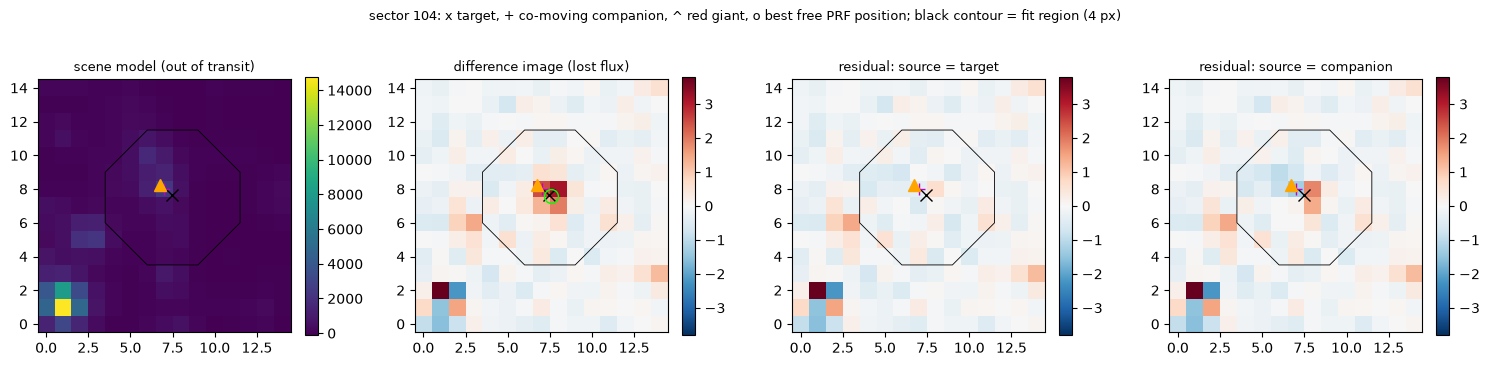

In [6]:
sec = 104
r = res[sec]
tab = r["table"].set_index("ID")
tx, ty = r["target"]
it = list(r["sources"].ID).index(GAIA_TARGET)
ic = list(r["sources"].ID).index(5925373272850782208)
ig = list(r["sources"].ID).index(5925373268528684288)
stamps = r["scene"]["stamps"]
m_t = tab.loc[GAIA_TARGET, "lost_flux"] * stamps[it]
m_c = tab.loc[5925373272850782208, "lost_flux"] * stamps[ic]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
vmax = np.nanmax(np.abs(r["diff"]))
for a, img, ttl in zip(ax, [r["scene"]["model"], r["diff"], r["diff"] - m_t, r["diff"] - m_c],
                       ["scene model (out of transit)", "difference image (lost flux)", "residual: source = target",
                        "residual: source = companion"]):
    im = a.imshow(img, origin="lower", cmap="viridis" if a is ax[0] else "RdBu_r",
                  vmin=None if a is ax[0] else -vmax, vmax=None if a is ax[0] else vmax)
    a.set_title(ttl, fontsize=9)
    a.contour(r["mask"], levels=[0.5], colors="k", linewidths=0.6)
    for i, mk, cl in [(it, "x", "k"), (ic, "+", "m"), (ig, "^", "orange")]:
        a.plot(r["sources"].x[i], r["sources"].y[i], mk, color=cl, ms=8)
    plt.colorbar(im, ax=a, fraction=0.046)
ax[1].plot(r["free"]["x"], r["free"]["y"], "o", mfc="none", mec="lime", ms=10)
fig.suptitle(f"sector {sec}: x target, + co-moving companion, ^ red giant, o best free PRF position; "
             "black contour = fit region (4 px)", fontsize=9)
plt.tight_layout()

In [7]:
show = {GAIA_TARGET: "target", 5925373272827260544: "3.2\" nbr", 5925373272827262208: "5.4\" nbr",
        5925373272850782208: "companion", 5925373272827253632: "comp. 0.4\" src", 5925373268528684288: "red giant"}
rows = []
for sec, r in res.items():
    t = r["table"].set_index("ID")
    for sid, name in show.items():
        rows.append(dict(sector=sec, star=name, sep_px=t.sep_px.get(sid, np.nan),
                         dchi2=t.dchi2_vs_target.get(sid, np.nan), depth_needed=t.depth_needed.get(sid, np.nan)))
dc = pd.DataFrame(rows)
piv = dc.pivot(index="star", columns="sector", values="dchi2")[SECTORS]
piv["sum (39-104)"] = piv[[39, 66, 93, 103, 104]].sum(axis=1)
piv["sum (all)"] = piv[SECTORS].sum(axis=1)
dn = dc.groupby("star").depth_needed.median()
piv["depth needed"] = dn
print("chi2(star) - chi2(target) for the difference-image fit; positive = worse than the target")
piv.loc[list(show.values())].round(2)

chi2(star) - chi2(target) for the difference-image fit; positive = worse than the target


sector,12,39,66,93,103,104,sum (39-104),sum (all),depth needed
star,,,,,,,,,
target,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.02
"3.2"" nbr",-2.87,5.54,-0.70,-5.23,1.20,3.95,4.76,1.88,0.52
"5.4"" nbr",-3.52,14.16,1.04,0.94,3.68,7.41,27.23,23.71,0.67
companion,4.00,23.04,-2.02,21.82,17.94,25.29,86.07,90.07,0.03
"comp. 0.4"" src",5.43,23.35,-0.94,25.71,21.51,27.27,96.89,102.32,0.16
red giant,14.25,57.50,6.29,74.65,32.16,38.89,209.49,223.74,0.00


In [8]:
# sensitivity to the in-transit window: the same test with a shorter window, and with the whole transit
sens = []
for label, dur in [("1.0 h", 1.0 / 24), (f"T23 = {DUR_IN * 24:.2f} h", DUR_IN), (f"T14 = {DUR14 * 24:.2f} h", DUR14)]:
    tot = {name: 0.0 for name in ["companion", "red giant", "3.2\" nbr"]}
    offs = []
    for sec in [39, 66, 93, 103, 104]:
        rr = pf.source_test(res[sec]["tpf"], src, P, T0, dur, res[sec]["prf"], GAIA_TARGET, epoch=2016.0,
                            tmag_max_cand=17.5, n_null=30)
        t = rr["table"].set_index("ID")
        for sid, name in [(5925373272850782208, "companion"), (5925373268528684288, "red giant"),
                          (5925373272827260544, "3.2\" nbr")]:
            tot[name] += t.dchi2_vs_target.get(sid, np.nan)
        offs.append(rr["free"]["offset_sigma"])
    sens.append(dict(window=label, **{f"sum dchi2 {n}": v for n, v in tot.items()},
                     max_free_offset_sigma=max(offs)))
pd.DataFrame(sens).round(1)

,window,sum dchi2 companion,sum dchi2 red giant,"sum dchi2 3.2"" nbr",max_free_offset_sigma
0,1.0 h,92.8,212.2,0.6,2.9
1,T23 = 1.22 h,91.1,222.4,6.4,2.2
2,T14 = 1.71 h,59.9,126.2,-4.3,2.9


**What this says.**

* **The co-moving companion and the red giant are excluded.** In four of the five good sectors,
  putting the source on the companion is worse than putting it on the target by Δχ² ≈ 18–25. The
  exception is sector 66, where they tie (Δχ² = −2). Summed over sectors 39–104 this is Δχ² ≈ 86,
  about 9σ. The same holds for the extra source 0.4″ from the companion (Δχ² ≈ 97). The red giant
  is worse in every sector, by 6 to 75, and by 209 in total.
* **The free fit agrees.** A single PRF free to move lands 0.07–0.37 px from the target in every
  sector (0.5–2.2σ). The companion would be 0.56 px away and the giant 0.85 px.
* **The result does not depend on the in-transit window** (sensitivity cell). With a 1-hour
  window or the full-depth window T23 it is the same. Using the whole transit T14 mixes partial-depth
  points into the average: it weakens the test (Δχ² ≈ 60 and 126), but does not reverse it.
* **The faint 3–5″ neighbours cannot be excluded by pixels.** The 3.2″ star ties with the target
  (Δχ² swings between −5 and +6 from sector to sector, +5 in total), as expected for a star only
  0.15 px away. The 5.4″ star (0.27 px) is mildly disfavoured (Δχ² ≈ 27). As hosts they would need
  40–65 % eclipses, so they can only be the source if they are eclipsing binaries. §6 deals with them.
* The lost flux divided by the target's scene flux gives a depth of ≈ 1.5–2 % per sector. That is
  close to QLP's deblended 1.4 %, as it should be if the dip is on the target.

One caveat: the scene model leaves 5–11 % of the out-of-transit light unexplained, from PRF errors
and from stars fainter than the catalogue cut. The companion test is a fit to the *difference*
image, where those errors largely cancel. It is consistent across four sectors with different
cameras, CCDs and pointings, which argues against a PRF artefact.

## 5. Does the depth change with the aperture as it should?

A simpler version of the same idea, which observers often use: measure the depth in apertures of
different size and position. If the target is the source, the depth (lost flux over the total stellar
flux in the aperture) is largest in a small aperture on the target. An aperture shifted towards the
companion or the giant collects relatively more of *their* light and the depth drops. If a neighbour
is the source, the depth peaks on the neighbour instead. For each hypothesis the scene model predicts
the depth in every aperture. We compare those predictions with the measured depths, using the scatter
of the same quantity in the fake-transit images as the error.

In [9]:
def disk(shape, x, y, rad):
    yy, xx = np.indices(shape)
    return np.hypot(xx - x, yy - y) <= rad

hyp = {"target": GAIA_TARGET, "companion": 5925373272850782208, "red giant": 5925373268528684288,
       "3.2\" nbr": 5925373272827260544}
rows, chi = [], {h: 0.0 for h in hyp}
for sec in [39, 66, 93, 103, 104]:
    r = res[sec]
    ids = list(r["sources"].ID)
    sx, sy = r["sources"].x.to_numpy(), r["sources"].y.to_numpy()
    tx, ty = r["target"]
    model, bkg, diff, nulls = r["scene"]["model"], r["scene"]["bkg"], r["diff"], r["nulls"]
    cx, cy = sx[ids.index(hyp["companion"])], sy[ids.index(hyp["companion"])]
    gx, gy = sx[ids.index(hyp["red giant"])], sy[ids.index(hyp["red giant"])]
    aps = {"r=1 px on target": disk(diff.shape, tx, ty, 1.0), "r=2 px on target": disk(diff.shape, tx, ty, 2.0),
           "r=3 px on target": disk(diff.shape, tx, ty, 3.0),
           "r=1 px on companion": disk(diff.shape, cx, cy, 1.0), "r=1 px on giant": disk(diff.shape, gx, gy, 1.0),
           "r=1 px, 1 px beyond companion": disk(diff.shape, tx + 2 * (cx - tx) / np.hypot(cx - tx, cy - ty),
                                                 ty + 2 * (cy - ty) / np.hypot(cx - tx, cy - ty), 1.0)}
    tab = r["table"].set_index("ID")
    for name, ap in aps.items():
        star_flux = (model[ap] - bkg).sum()
        meas = diff[ap].sum() / star_flux
        err = np.std([n[ap].sum() for n in nulls]) / star_flux
        row = dict(sector=sec, aperture=name, measured=meas, err=err)
        for h, sid in hyp.items():
            j = ids.index(sid)
            a = tab.lost_flux.get(sid, np.nan)
            if not np.isfinite(a):  # star not in the candidate list: fit its amplitude here
                a = pf.fit_sources(diff, r["sigma"], r["scene"]["stamps"][[j]], r["mask"])[0, 0]
            row[h] = pf.predicted_depth(a, r["scene"]["stamps"][j], model, bkg, ap)
            chi[h] += ((meas - row[h]) / err) ** 2
        rows.append(row)
ap_tab = pd.DataFrame(rows)
print("chi2 of the aperture depths (30 apertures, 5 sectors) under each hypothesis:")
print({h: round(v, 1) for h, v in chi.items()})
(ap_tab.groupby("aperture", sort=False)[["measured", "err"] + list(hyp)].mean() * 100).round(2).rename(
    columns=lambda c: c + " [%]")

chi2 of the aperture depths (30 apertures, 5 sectors) under each hypothesis:
{'target': np.float64(35.4), 'companion': np.float64(45.8), 'red giant': np.float64(86.6), '3.2" nbr': np.float64(31.0)}


,measured [%],err [%],target [%],companion [%],red giant [%],"3.2"" nbr [%]"
aperture,,,,,,
r=1 px on target,0.18,0.04,0.17,0.16,0.09,0.18
r=2 px on target,0.12,0.02,0.11,0.12,0.08,0.11
r=3 px on target,0.07,0.02,0.07,0.08,0.06,0.08
r=1 px on companion,0.13,0.04,0.11,0.14,0.10,0.11
r=1 px on giant,0.10,0.04,0.08,0.13,0.10,0.09
"r=1 px, 1 px beyond companion",0.02,0.03,0.02,0.06,0.07,0.03


The table shows depths in percent, averaged over sectors 39–104. "measured" is the data; the other
columns are the depths each hypothesis predicts. The depths are only 0.1–0.2 % because these
apertures are not deblended. The red giant is 4.7× brighter than the target in the TESS band and
dominates the light within a few pixels. The χ² line is the formal summary: 35 for the target, 31
for the 3.2″ neighbour, 46 for the companion and 87 for the giant, from 30 aperture depths.
Apertures that overlap are correlated, so read these as a ranking, not as exact probabilities.

The pattern is the one the PRF fit found:

* in a small aperture on the target the measured depth is close to what a target source predicts;
* a source on the companion or the giant would make the depth *grow* towards those stars. It
  doesn't.
* the 3.2″ neighbour predicts nearly the same pattern as the target, because it is in almost the
  same place.

The aperture test is weaker than the PRF fit (it throws away the spatial information inside each
aperture), but it agrees with it and is easy to repeat with any photometry tool.

## 6. Can the transit shape rule out the faint neighbours? The maximum-dilution test

The pixels cannot separate stars 3–5″ apart. The **shape** of the transit can still exclude them.
A diluted eclipse of a faint star must be deep on that star (here 45–65 %). A deep eclipse has
long ingress and egress compared with its total duration, because the eclipsing body is large
relative to the star it covers. A shallow, box-shaped transit with short ingress and egress can only
come from a small body. Vanderburg et al. (2019, ApJL 881, L19) turned this into a bound on how much
fainter than the target the true host can be:

$$\Delta m \le 2.5\,\log_{10}\!\left(\frac{T_{12}^2}{T_{13}^2\,\delta}\right),$$

where $T_{12}$ is the ingress time, $T_{13}$ the time from first to third contact and δ the observed
depth. We evaluate it for every sample of the MCMC transit fit (six sectors, supersampled for the
long cadences), which gives a posterior for the largest Δm the shape allows.

Two details make the test conservative. Long-cadence smearing could only make ingress look *longer*,
which loosens the bound. And the QLP depth is already deblended to the target, so Δm is measured
relative to the target, as the formula requires.

T14 = 1.71 h, T12 = 0.23 h; largest allowed Delta m: median 0.67, 84 % 1.71, 95 % 2.22, 99.7 % 3.14
3.2" neighbour      : Delta T = 3.69 mag -> fraction of posterior samples that allow it: 0.0006
5.4" neighbour      : Delta T = 4.04 mag -> fraction of posterior samples that allow it: 0.0005
co-moving companion : Delta T = 0.34 mag -> fraction of posterior samples that allow it: 0.6350


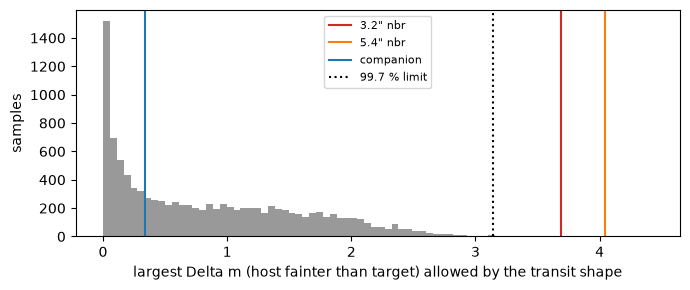

In [10]:
T12 = (T14 - T23) / 2
T13 = T14 - T12
dm_max = 2.5 * np.log10(T12**2 / (T13**2 * k_**2))
lims = np.percentile(dm_max, [50, 84, 95, 99.7])
print(f"T14 = {np.median(T14) * 24:.2f} h, T12 = {np.median(T12) * 24:.2f} h; "
      f"largest allowed Delta m: median {lims[0]:.2f}, 84 % {lims[1]:.2f}, 95 % {lims[2]:.2f}, 99.7 % {lims[3]:.2f}")
for sid, name in [(5925373272827260544, "3.2\" neighbour"), (5925373272827262208, "5.4\" neighbour"),
                  (5925373272850782208, "co-moving companion")]:
    dT = gaia.loc[gaia.Source == sid, "dT"].iloc[0]
    print(f"{name:20s}: Delta T = {dT:.2f} mag -> fraction of posterior samples that allow it: {np.mean(dm_max >= dT):.4f}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(dm_max, bins=80, color="0.6")
for sid, c in [(5925373272827260544, "C3"), (5925373272827262208, "C1"), (5925373272850782208, "C0")]:
    ax.axvline(gaia.loc[gaia.Source == sid, "dT"].iloc[0], color=c, label=show[sid])
ax.axvline(lims[3], color="k", ls=":", label="99.7 % limit")
ax.set_xlabel("largest Delta m (host fainter than target) allowed by the transit shape")
ax.set_ylabel("samples")
ax.legend(fontsize=8)
plt.tight_layout()

**What this says.** The transit is too box-shaped for a deep eclipse on a faint star. The shape
allows a host at most ~3.1 mag fainter than the target (99.7 % of the posterior). The 3.2″ and 5.4″
neighbours are 3.7 and 4.0 mag fainter. Only ~0.05 % of the posterior samples allow them: the
grazing tail of the impact-parameter distribution. That is a ≈3.5σ exclusion. The companion is
only 0.34 mag fainter, so the shape cannot exclude it; the pixels did (§4).

Together, §4 and §6 exclude every Gaia star that could make the dip, except the target.

## 7. Do other surveys see stars that Gaia missed?

Gaia resolves pairs down to about 0.5–1″. A source Gaia missed would have to be very close to the
target or very faint. We compare Gaia with two catalogues of the same patch of sky: 2MASS (near-IR,
1999) and SkyMapper DR4 (optical, southern sky). Pan-STARRS and ZTF do not reach declination −51°.
At 2MASS's epoch the target's high proper motion (−114, +86 mas/yr) puts it 2.4″ from its 2016
position, so we compare positions moved to each catalogue's epoch. We also check ExoFOP for existing
TOIs, CTOIs and high-resolution imaging.

In [11]:
from astropy.time import Time

def at_epoch(df, year):
    dt = year - 2016.0
    dec = df.DE_ICRS + df.pmDE.fillna(0) / 3.6e6 * dt
    ra = df.RA_ICRS + df.pmRA.fillna(0) / 3.6e6 * dt / np.cos(np.radians(df.DE_ICRS))
    return SkyCoord(ra.values, dec.values, unit="deg")

near = gaia[gaia.sep < 20]
for cat, ra_c, de_c, ep, label in [("II/246/out", "RAJ2000", "DEJ2000", 1999.5, "2MASS"),
                                   ("II/379/smssdr4", "RAICRS", "DEICRS", None, "SkyMapper DR4")]:
    t = Vizier(row_limit=-1, columns=["**"]).query_region(c0, radius=20 * u.arcsec, catalog=cat)
    d = t[0].to_pandas() if t else pd.DataFrame()
    if d.empty:
        print(f"{label}: no sources")
        continue
    year = ep if ep else Time(np.nanmedian(d.EpMean), format="mjd").jyear
    gc = at_epoch(near, year)
    cc = SkyCoord(d[ra_c].values, d[de_c].values, unit="deg")
    idx, sep2d, _ = cc.match_to_catalog_sky(gc)
    d["gaia_match_sep"] = sep2d.arcsec
    d["gaia_G"] = near.Gmag.values[idx]
    d["gaia_sep_from_target"] = near.sep.values[idx]
    unmatched = d[d.gaia_match_sep > 1.5]
    print(f"{label} (epoch {year:.1f}): {len(d)} sources within 20\", {len(unmatched)} without a Gaia source within 1.5\"")
    if len(unmatched):
        print(unmatched[[ra_c, de_c, "gaia_match_sep", "gaia_G", "gaia_sep_from_target"]].round(3).to_string(index=False))

toi = pd.read_csv(OUT / "archive" / "toi_2026-10-18.csv", comment="#", low_memory=False)
ctoi = pd.read_csv(OUT / "archive" / "ctoi_2026-10-18.csv", comment="#", low_memory=False)
tic_near = {214311908, 214311910, 1515709367, 214311906, 214311955}
print(f"\nExoFOP TOI list ({len(toi)} rows) and CTOI list ({len(ctoi)} rows), downloaded 2026-10-18: "
      f"entries for the target or its neighbours: {toi['TIC ID'].isin(tic_near).sum()} TOIs, "
      f"{ctoi.iloc[:, 0].isin(tic_near).sum()} CTOIs")

2MASS (epoch 1999.5): 5 sources within 20", 0 without a Gaia source within 1.5"
SkyMapper DR4 (epoch 2019.0): 11 sources within 20", 1 without a Gaia source within 1.5"
 RAICRS  DEICRS  gaia_match_sep  gaia_G  gaia_sep_from_target
 260.97 -51.318            5.39   18.45                19.531

ExoFOP TOI list (8151 rows) and CTOI list (5138 rows), downloaded 2026-10-18: entries for the target or its neighbours: 0 TOIs, 0 CTOIs


**What this says.**

* **2MASS and SkyMapper find no star that Gaia lacks.** The few apparently unmatched entries are
  blends of the target with its 3″ neighbour, or of the companion pair, in the coarser older images.
  None is near enough and bright enough to matter. Pan-STARRS, ZTF and the Legacy Survey do not cover
  this field.
* **ExoFOP lists neither the target nor any neighbour as a TOI or CTOI**, so the signal is
  still unreported. ExoFOP's target pages are rendered by JavaScript and its bulk imaging endpoint
  did not answer scripted requests today, so we could not query imaging programmatically. Imaging is
  almost always taken only for TOIs and CTOIs, so none is expected for a star that is neither. High-resolution imaging (speckle or AO)
  would be the first request after a CTOI. It would probe companions between ~0.05″ and 1″, the gap
  that Gaia and the transit shape leave.

## 8. What does this do to the false-positive probability?

TRICERATOPS (Giacalone et al. 2021) compares the likelihood of the light curve under each scenario:
a planet on the target (TP), an eclipsing binary on the target (EB), scenarios with an unresolved
bound companion, background stars from a TRILEGAL simulation, and a planet or eclipsing binary on
each **catalogued neighbour** (NTP, NEB, NEBx2P). It weights each by a prior. The FPP is the total
probability of everything except a planet on the target.

The table below is the latest stored run (agent C's, with TRILEGAL background stars).

In [12]:
summary = json.loads((OUT / "summary.json").read_text())  # re-read: the FPP may have been re-run meanwhile
fpp = summary.get("fpp", {})
print(f"stored FPP = {fpp.get('FPP')}, NFPP = {fpp.get('NFPP')}, method: {fpp.get('fpp_method')}, "
      f"runs: {fpp.get('n_runs')}")
scen = pd.DataFrame(fpp.get("scenarios", []))
star_role = {"214311908": "target", "214311906": "red giant (LPV) at 17.8\"",
             "214311910": "co-moving companion (TIC 'SPLIT' entry)", "1515709367": "co-moving companion (TIC duplicate)",
             "214311955": "star 31\" away"}
scen["star"] = scen.ID.astype(str).map(star_role).fillna("other")
scen.round(4)

stored FPP = 0.8524551131363335, NFPP = 0.8468525638436176, method: triceratops + TRILEGAL 1.6, runs: 5


,scenario,ID,prob,star
0,NTP,214311906,0.4387,"red giant (LPV) at 17.8"""
1,TP,214311908,0.1358,target
2,NEB,214311910,0.1213,co-moving companion (TIC 'SPLIT' entry)
3,NEB,1515709367,0.1003,co-moving companion (TIC duplicate)
4,NTP,214311910,0.0579,co-moving companion (TIC 'SPLIT' entry)
5,NEBx2P,214311906,0.0473,"red giant (LPV) at 17.8"""
6,NTP,1515709367,0.0333,co-moving companion (TIC duplicate)
7,NEB,214311955,0.0238,"star 31"" away"


**Two problems with this number.**

1. **The neighbours get the Sun's parameters.** TRICERATOPS needs a mass, radius and temperature
   for each neighbour, and takes them from the TIC. TIC 214311906 (the red giant) and TIC 214311910 /
   1515709367 (the companion's "SPLIT" and "DUPLICATE" entries) have none. For a star without
   parameters TRICERATOPS silently assumes a **Sun-like star**: `triceratops.py`, "if a property is
   unknown, assume solar value". A 1.7-hour transit is easy to fit around a Sun-like star at
   5.69 days. Around the real giant it is impossible (§3).
   That is why the single largest scenario is "a planet on TIC 214311906" (NTP, ~0.44).
2. **The scenarios ignore the pixel evidence.** By construction TRICERATOPS treats every neighbour
   inside the aperture as a possible host. Its documentation suggests removing stars that follow-up
   has ruled out. §4 rules out the companion, its 0.4″ partner, the red giant and the star 31″ away at
   high significance.

Removing the scenarios on excluded stars and renormalising gives an estimate. Only the top
scenarios are stored, so we treat the unstored remainder (1 − Σ stored) as false positives, which
gives an **upper bound**:

In [13]:
excluded = {"214311906", "214311910", "1515709367", "214311955"}
if len(scen):
    kept = scen[~scen.ID.astype(str).isin(excluded)]
    rest = max(0.0, 1 - scen.prob.sum())
    tp = kept.loc[kept.scenario == "TP", "prob"].sum()
    fpp_up = 1 - tp / (kept.prob.sum() + rest)
    fpp_lo = 1 - tp / (kept.prob.sum())
    print(f"stored scenarios: {scen.prob.sum():.3f} of the probability; unstored remainder {rest:.3f}")
    print(f"FPP with the pixel-excluded stars removed: {fpp_lo:.2f} (remainder ignored) to {fpp_up:.2f} "
          f"(remainder counted as false positive)")
pix = {"excluded_tic": sorted(excluded),
       "excluded_gaia_dr3": [5925373272850782208, 5925373272827253632, 5925373268528684288],
       "reason": {"214311906": "red giant / LPV (Gaia vclassre LPV, ASAS-SN Mira P~294 d); PRF fit dchi2 > 8-63 per sector",
                  "214311910": "co-moving companion; PRF fit dchi2 ~88 (sectors 39-104) vs target",
                  "1515709367": "TIC duplicate of the co-moving companion",
                  "214311955": "31\" away (1.5 px); PRF fit dchi2 > 25 in every 200-s sector"},
       "shape_excluded_gaia_dr3": [5925373272827260544, 5925373272827262208],
       "shape_limit_dm_99.7": float(lims[3]),
       "notebook": "notebooks/candidate-TIC214311908.ipynb"}
(OUT / "pixel_excluded.json").write_text(json.dumps(pix, indent=2))
print("saved", OUT / "pixel_excluded.json")

stored scenarios: 0.959 of the probability; unstored remainder 0.041
FPP with the pixel-excluded stars removed: 0.00 (remainder ignored) to 0.23 (remainder counted as false positive)
saved ../data/followup/214311908/pixel_excluded.json


This is an estimate, not a proper run: the scenario probabilities interact through the
normalisation, and the remainder includes the target-EB, companion and background scenarios. The
honest next step is to **re-run TRICERATOPS** with the excluded stars dropped from its star table,
and with Gaia-based parameters for any neighbour that stays in. `pixel_excluded.json` lists them for
`src/followup.py`. Nothing here suggests the remaining false-positive scenarios are large. The TRILEGAL
background probability is 2×10⁻⁵, the companion scenarios add 0.003 and the target-EB adds 0.002.

## 9. What should a ground-based observer do?

The scenarios TESS cannot close are: an eclipsing binary on one of the faint 3–5″ neighbours
(disfavoured at ~3.5σ by the shape), and a bound or background eclipsing binary closer than ~1″. A
ground-based light curve with 1–2″ seeing separates the target from the 3″ neighbour. It also gives
a second, independent depth in a different colour: a planet's depth is the same in every band, but a
blend of stars with different colours gives different depths. The predictions an observer needs:

* **when**: transit midtimes with their uncertainties, propagated from the MCMC samples (which keeps
  the P–T0 correlation);
* **from where**: the star is at declination −51°, so southern sites. RA 17h24m means it is best
  placed in the middle of the year; between October and April it is only up in the evening (October)
  or before dawn (from February). We list transits with the star more than 30° high and the Sun below
  −12° from ingress to egress, at Cerro Tololo, Sutherland (SAAO) and Siding Spring;
* **what depth**: about 1.4 % on the target. If one of the neighbours were the source, a small
  aperture on that neighbour would show the depths below, and an aperture on the target alone would
  show no dip.

In [14]:
from astropy.coordinates import AltAz, EarthLocation, get_sun

start, stop = Time("2026-10-18"), Time("2027-04-18")
n0 = int(np.ceil((start.jd - 2457000 - T0) / P))
n1 = int(np.floor((stop.jd - 2457000 - T0) / P))
tc_med = fit["T0"]["median"]
rng = np.random.default_rng(1)
samp = chain[rng.choice(len(chain), 4000, replace=False)]
sites = {"CTIO": EarthLocation(lat=-30.169 * u.deg, lon=-70.806 * u.deg, height=2207 * u.m),
         "SAAO": EarthLocation(lat=-32.379 * u.deg, lon=20.811 * u.deg, height=1798 * u.m),
         "SSO": EarthLocation(lat=-31.273 * u.deg, lon=149.071 * u.deg, height=1165 * u.m)}
target_c = SkyCoord(star.ra, star.dec, unit="deg")
half = DUR14 / 2
rows = []
for n in range(n0, n1 + 1):
    tc = samp[:, 0] + n * samp[:, 1]
    mid, sig = np.median(tc), np.std(tc)
    t_in, t_eg = Time(mid - half + 2457000, format="jd"), Time(mid + half + 2457000, format="jd")
    row = dict(epoch=n, mid_BTJD=mid, mid_UTC=Time(mid + 2457000, format="jd").iso[:16], sigma_min=sig * 1440,
               ingress_UTC=t_in.iso[:16], egress_UTC=t_eg.iso[:16])
    times = Time(np.linspace(t_in.jd, t_eg.jd, 5), format="jd")
    for name, loc in sites.items():
        fr = AltAz(obstime=times, location=loc)
        alt = target_c.transform_to(fr).alt.deg
        sun = get_sun(times).transform_to(fr).alt.deg
        row[f"{name}_alt_min"] = alt.min()
        row[name] = bool((alt > 30).all() and (sun < -12).all())
    rows.append(row)
eph = pd.DataFrame(rows)
eph.to_csv(OUT / "ephemeris.csv", index=False)
print(f"{len(eph)} transits between {start.iso[:10]} and {stop.iso[:10]}; timing uncertainty "
      f"{eph.sigma_min.min():.1f}-{eph.sigma_min.max():.1f} min (1 sigma); saved {OUT / 'ephemeris.csv'}")
obs = eph[eph[list(sites)].any(axis=1)]
print(f"observable (whole transit, alt > 30 deg, Sun < -12 deg) from at least one site: {len(obs)}")
obs[["epoch", "mid_UTC", "sigma_min", "ingress_UTC", "egress_UTC"] + list(sites)].round(1)

32 transits between 2026-10-18 and 2027-04-18; timing uncertainty 2.1-2.3 min (1 sigma); saved ../data/followup/214311908/ephemeris.csv
observable (whole transit, alt > 30 deg, Sun < -12 deg) from at least one site: 5


,epoch,mid_UTC,sigma_min,ingress_UTC,egress_UTC,CTIO,SAAO,SSO
21,106,2027-02-19 02:20,2.3,2027-02-19 01:29,2027-02-19 03:11,False,True,False
27,112,2027-03-25 05:55,2.3,2027-03-25 05:03,2027-03-25 06:46,True,False,False
29,114,2027-04-05 15:06,2.3,2027-04-05 14:15,2027-04-05 15:57,False,False,True
30,115,2027-04-11 07:42,2.3,2027-04-11 06:51,2027-04-11 08:33,True,False,False
31,116,2027-04-17 00:18,2.3,2027-04-16 23:26,2027-04-17 01:09,False,True,False


In [15]:
exp = gaia[gaia.Source.isin([GAIA_TARGET, 5925373272827260544, 5925373272827262208, 5925373272850782208])][
    ["Source", "sep", "Gmag", "Tmag", "depth_needed"]].copy()
exp["role"] = exp.Source.map(roles)
exp["depth in a small aperture on this star, if it is the source [%]"] = (exp.depth_needed * 100).round(1)
print("expected depths (TESS band; the companion and the red giant are already excluded by the pixels)")
exp[["role", "sep", "Gmag", "Tmag", "depth in a small aperture on this star, if it is the source [%]"]].round(2)

expected depths (TESS band; the companion and the red giant are already excluded by the pixels)


,role,sep,Gmag,Tmag,"depth in a small aperture on this star, if it is the source [%]"
0,target,0.00,14.28,13.13,1.4
1,"3.2"" neighbour",3.13,17.48,16.82,41.0
6,"5.4"" neighbour",5.72,17.68,17.18,56.8
14,co-moving companion,11.73,14.65,13.48,1.9


**When it can be seen.** Between now and mid-April 2027 only five transits are fully observable
from these three sites: 19 Feb (SAAO), 25 Mar (CTIO), 5 Apr (Siding Spring), 11 Apr (CTIO) and
17 Apr (SAAO). The star is too close to the Sun from November to January. Observing improves from
May, when the star is up most of the night. The 1σ timing uncertainty is 2.3 minutes, far below the
transit duration, so the predicted windows are reliable. The full list, with altitudes, is in
`data/followup/214311908/ephemeris.csv`.

**Recommended observation.** A full transit (1.7 h plus at least 1 h of baseline on each side) with a
0.4–1 m telescope in a red band (r′, i′ or z′; an M dwarf is brightest there). Keep the aperture
radius ≤ 2″ so the 3.2″ neighbour stays out. Also extract a light curve of that neighbour: if it were
the source it would show a ~40 % eclipse, impossible to miss even at G = 17.5. A depth of ~1.4 % on
the target, on time, with the same depth in two bands, would close the faint-neighbour scenario. A
transit observed early or late would also refine the ephemeris.

## 10. Verdict

| test | result |
|---|---|
| repeats | yes: same depth and period in six sectors over 7 years (notebook 9) |
| transit shape and density | U-shaped; stellar density from the fit matches the catalogue (ratio ≈ 0.9–1.0) |
| neighbours bright enough to cause it | the co-moving companion, a red giant, two faint 3–5″ stars, a few more beyond 10″ |
| PRF pixel fit, 6 sectors | companion excluded (Δχ² ≈ 86, ≈ 9σ), red giant excluded (Δχ² ≈ 209); free position on the target in every sector |
| aperture depths | follow the target hypothesis |
| transit-shape dilution limit | host at most ~3.1 mag fainter (99.7 %): the 3–5″ neighbours excluded at ≈3.5σ |
| Gaia quality of the target | single-looking: RUWE 1.08, no double peaks, no orbit |
| other catalogues | no star missing from Gaia; not a TOI or CTOI |
| TRICERATOPS FPP as run | 0.85, dominated by neighbours with solar default parameters that the pixels exclude |
| FPP with those stars removed (estimate) | ≤ 0.23 (upper bound from the stored scenarios) |

**Conclusion: the evidence now supports a CTOI.** TESS data have closed every resolved-neighbour
scenario that kept the candidate "unresolved". The companion and the giant are excluded by the
pixels, and the faint close neighbours by the transit shape. The FPP above 0.5 comes from a known
weakness: TRICERATOPS gives Sun-like parameters to neighbours missing from the TIC. It is not
evidence against the planet.

Before submitting, keep two things straight:

1. **Re-run TRICERATOPS with the excluded stars removed** (`pixel_excluded.json`) and confirm that
   the FPP falls below 0.5. Our reporting rule asks for a computed FPP, not an estimate.
2. **The CTOI should say what is still open**: an unresolved companion closer than ~1″ (high-resolution
   imaging), and the faint-neighbour EB at ~3.5σ (a ground-based transit with a small aperture, §9).
   Both are standard TFOP follow-up, and both are cheap for a T = 13 M dwarf with a 1.4 % dip.

If confirmed, this would be a ~4.9 R⊕ planet on a 5.7-day orbit around a 0.37 M☉ M dwarf in a
hierarchical triple system at 64 pc. Planets of this size are rare around M dwarfs, so it would be
worth the follow-up.